In [1]:
import sys
sys.path.append("..")

import numpy as np
import tensorflow as tf

from functions import BunDLeNet, BunDLeTrainer
from data_reader import DataReader
from processed_data_storage import ProcessedDataStroage
from preprocess import Preprocessor

# "Trainingsepoche" = ein Durchlauf durch alle Trainingsfenster.
# Nicht verwechseln mit den EEG-Epochen (Zeitabschnitte um ein Bild herum).
number_of_training_epochs = 20
subjects_range = range(1, 2)

data_reader = DataReader()
processed_data_storage = ProcessedDataStroage()
train_category_per_epochs_all_subs = []
test_category_per_epochs_all_subs = []
for sub in subjects_range:
    subject = sub + 100
    subject = str(subject)
    raw, channels, events = data_reader.read_data(
        subject=str(subject),
    )

    preprocessor = Preprocessor(raw)
    del raw

    preprocessor.run_pipeline(use_filter=True, use_ica=False, use_autoreject=False)

    epochs_train, epochs_test = preprocessor.split_train_test()

    X_train, X_test = preprocessor.scale(epochs_train.get_data(), epochs_test.get_data())
    
    labels_train, train_category_per_epoch = preprocessor.create_labels_for_epochs(epochs_train)    # Form (1638, 120)
    train_category_per_epochs_all_subs.append(train_category_per_epoch)
    
    labels_test,test_category_per_epoch = preprocessor.create_labels_for_epochs(epochs_test)      # Form (410, 120)
    test_category_per_epochs_all_subs.append(test_category_per_epoch)
    
    processed_data_storage.save_subject(subject, {"X_train": X_train, "X_test": X_test, "labels_train": labels_train, "labels_test": labels_test})

I0000 00:00:1795109628.174143   86125 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795109628.206810   86125 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795109629.155442   86125 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


None
Arbeitsverzeichnis: /home/bened/bachelor-thesis/notebooks/BunDLe-Net/notebooks
Datenverzeichnis: /home/bened/bachelor-thesis/data/raw/ds005363-download
Lese BrainVision-Aufnahme ein: /home/bened/bachelor-thesis/data/raw/ds005363-download/sub-101/ses-01/eeg/sub-101_ses-01_task-objrecog_eeg.vhdr
Filtering raw data in 1 contiguous segment
Setting up high-pass filter at 1 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal highpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Filter length: 3301 samples (3.301 s)

Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.019

In [2]:
X_train = []
X_test = []
labels_train = []
labels_test = []

for sub in subjects_range:
    subject = sub + 100
    values = processed_data_storage.load_subject(subject)
    X_train.append(values[0])
    X_test.append(values[1])
    labels_train.append(values[2])
    labels_test.append(values[3])

X_train = np.concatenate(X_train, axis=0)
X_test = np.concatenate(X_test, axis=0)
labels_train = np.concatenate(labels_train, axis=0)
labels_test = np.concatenate(labels_test, axis=0)
train_category_per_epochs_all_subs = np.concatenate(train_category_per_epochs_all_subs, axis=0)
test_category_per_epochs_all_subs = np.concatenate(test_category_per_epochs_all_subs, axis=0)

number_of_epochs, number_of_channels, number_of_time_points = X_train.shape
print(f"X_train shape: {X_train.shape}")
print(f"Number of epochs: {number_of_epochs}")
print(f"Number of channels: {number_of_channels}")

# Alle Fensterpaare der Trainingsdaten (darauf wird trainiert)
epoch_numbers, start_time_points = preprocessor.list_all_window_pairs(
    number_of_epochs, number_of_time_points, preprocessor.WINDOW_LENGTH
)

# Alle Fensterpaare der Testdaten (werden nur ausgewertet, nie trainiert)
number_of_test_epochs = X_test.shape[0]
number_of_test_time_points = X_test.shape[2]
test_epoch_numbers, test_start_time_points = preprocessor.list_all_window_pairs(
    number_of_test_epochs, number_of_test_time_points, preprocessor.WINDOW_LENGTH
)

# Feste Zufallsauswahl an Trainingsfenstern, genauso viele wie Testfenster.
# Auf dieser Auswahl messen wir nach jeder Trainingsepoche Loss und Genauigkeit
# auf genau dieselbe Art wie auf den Testdaten.
random_generator = np.random.default_rng(11)
train_subset_indices = random_generator.choice(
    len(epoch_numbers), size=len(test_epoch_numbers), replace=False
)
train_subset_epoch_numbers = epoch_numbers[train_subset_indices]
train_subset_start_time_points = start_time_points[train_subset_indices]

print(f"Trainingsfenster: {len(epoch_numbers)}, davon ausgewertet: {len(train_subset_epoch_numbers)}")
print(f"Testfenster: {len(test_epoch_numbers)}")

# Zufallswert (reines Raten) als Vergleichslinie.
# Das Ziel eines Fensterpaares ist das Label am Index start + WINDOW_LENGTH,
# also frühestens am Index WINDOW_LENGTH. Davor liegende Labels kommen als Ziel nie vor.
target_labels_that_can_occur = labels_train[:, preprocessor.WINDOW_LENGTH:]
target_categories = np.unique(target_labels_that_can_occur)
number_of_target_categories = len(target_categories)
chance_loss = np.log(number_of_target_categories)
chance_accuracy = 1 / number_of_target_categories
print(f"Kategorien, die als Ziel vorkommen: {target_categories}")
print(f"Raten ergibt Loss ln({number_of_target_categories}) = {chance_loss:.3f} und Genauigkeit {chance_accuracy:.2f}")

X_train shape: (1638, 64, 120)
Number of epochs: 1638
Number of channels: 64
Trainingsfenster: 171990, davon ausgewertet: 43050
Testfenster: 43050
Kategorien, die als Ziel vorkommen: [0. 1. 2. 3. 4.]
Raten ergibt Loss ln(5) = 1.609 und Genauigkeit 0.20


In [3]:
behaviour_loss_function = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)


def evaluate_windows(model, eeg_data, labels, epoch_numbers, start_time_points):
    """Berechnet Behavior-Loss und Genauigkeit auf den gegebenen Fensterpaaren.

    Das Modell wird dabei nicht verändert (kein Training).
    """
    sum_of_losses = 0.0
    number_of_correct_predictions = 0
    number_of_windows = len(epoch_numbers)

    for batch_start in range(0, number_of_windows, preprocessor.BATCH_SIZE):
        batch_end = batch_start + preprocessor.BATCH_SIZE

        window_pairs, target_labels = preprocessor.build_training_batch(
            eeg_data,
            labels,
            epoch_numbers[batch_start:batch_end],
            start_time_points[batch_start:batch_end],
            preprocessor.WINDOW_LENGTH,
        )
        target_labels = target_labels.astype(np.int64)

        # training=False schaltet die GaussianNoise-Schicht aus
        _, _, predicted_scores = model(
            tf.convert_to_tensor(window_pairs, dtype=tf.float32), training=False
        )

        # Der Loss ist ein Mittelwert über den Batch. Der letzte Batch ist kleiner,
        # deshalb gewichten wir mit der Batchgröße und teilen am Ende durch alle Fenster.
        batch_loss = float(behaviour_loss_function(target_labels, predicted_scores))
        number_of_windows_in_batch = len(target_labels)
        sum_of_losses = sum_of_losses + batch_loss * number_of_windows_in_batch

        # Vorhergesagte Kategorie = Ausgang mit dem höchsten Wert
        predicted_categories = np.argmax(predicted_scores.numpy(), axis=1)
        for window_number in range(number_of_windows_in_batch):
            if predicted_categories[window_number] == target_labels[window_number]:
                number_of_correct_predictions = number_of_correct_predictions + 1

    mean_loss = sum_of_losses / number_of_windows
    accuracy = number_of_correct_predictions / number_of_windows
    return mean_loss, accuracy

In [4]:
# Modell hier neu anlegen: Wenn man nur diese Zelle erneut ausführt,
# startet das Training von vorne statt mit dem alten Modell weiterzumachen.
model = BunDLeNet(3)
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
trainer = BunDLeTrainer(model, optimizer)

all_losses = []           # pro Batch: [Markov, Behavior, Total]
history_per_epoch = []    # pro Trainingsepoche: [Train-Loss, Train-Genauigkeit, Test-Loss, Test-Genauigkeit]
for training_epoch in range(number_of_training_epochs):
    shuffled_order = random_generator.permutation(len(epoch_numbers))
    for batch_start in range(0, len(shuffled_order), preprocessor.BATCH_SIZE):
        selected_pairs = shuffled_order[batch_start : batch_start + preprocessor.BATCH_SIZE]

        window_pairs, target_labels = preprocessor.build_training_batch(
            X_train,
            labels_train,
            epoch_numbers[selected_pairs],
            start_time_points[selected_pairs],
            preprocessor.WINDOW_LENGTH,
        )
        markov_loss, behaviour_loss, total_loss = trainer.train_step(
            tf.convert_to_tensor(window_pairs, dtype=tf.float32),
            tf.convert_to_tensor(target_labels, dtype=tf.int64),
            gamma=preprocessor.GAMMA,
        )
        all_losses.append([float(markov_loss), float(behaviour_loss), float(total_loss)])

    # Nach jeder Trainingsepoche: Training und Test auf dieselbe Art auswerten
    train_loss, train_accuracy = evaluate_windows(
        model, X_train, labels_train, train_subset_epoch_numbers, train_subset_start_time_points
    )
    test_loss, test_accuracy = evaluate_windows(
        model, X_test, labels_test, test_epoch_numbers, test_start_time_points
    )
    history_per_epoch.append([train_loss, train_accuracy, test_loss, test_accuracy])

    print(
        f"Trainingsepoche {training_epoch + 1}/{number_of_training_epochs}: "
        f"Loss Training {train_loss:.3f} / Test {test_loss:.3f}, "
        f"Genauigkeit Training {train_accuracy:.3f} / Test {test_accuracy:.3f}"
    )


W0000 00:00:1795109647.746111   86125 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1795109647.750010   86125 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1795109647.973170   86125 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9217 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5070, pci bus id: 0000:03:00.0, compute capability: 12.0a


Trainingsepoche 1/20: Loss Training 1.558 / Test 1.559, Genauigkeit Training 0.241 / Test 0.237
Trainingsepoche 2/20: Loss Training 1.511 / Test 1.513, Genauigkeit Training 0.255 / Test 0.245
Trainingsepoche 3/20: Loss Training 1.468 / Test 1.475, Genauigkeit Training 0.273 / Test 0.226
Trainingsepoche 4/20: Loss Training 1.447 / Test 1.459, Genauigkeit Training 0.280 / Test 0.228
Trainingsepoche 5/20: Loss Training 1.403 / Test 1.420, Genauigkeit Training 0.311 / Test 0.255
Trainingsepoche 6/20: Loss Training 1.369 / Test 1.391, Genauigkeit Training 0.335 / Test 0.275
Trainingsepoche 7/20: Loss Training 1.348 / Test 1.381, Genauigkeit Training 0.349 / Test 0.287
Trainingsepoche 8/20: Loss Training 1.327 / Test 1.379, Genauigkeit Training 0.361 / Test 0.286
Trainingsepoche 9/20: Loss Training 1.310 / Test 1.372, Genauigkeit Training 0.372 / Test 0.296
Trainingsepoche 10/20: Loss Training 1.295 / Test 1.368, Genauigkeit Training 0.379 / Test 0.298
Trainingsepoche 11/20: Loss Training 1.

In [ ]:
def compute_tau_values_per_epoch(eeg_data, labels, epoch_numbers, start_time_points):
    """Wendet das fertig trainierte tau auf alle Fenster an.

    Rückgabe hat die Form (Anzahl EEG-Epochen, latente Dimension, Anzahl Fensterpositionen),
    also dieselbe Form, die der SlidingEstimator auch bei den Rohdaten erwartet.
    Das Modell wird dabei nicht verändert (kein Training).
    """
    tau_values = []
    number_of_windows = len(epoch_numbers)

    for batch_start in range(0, number_of_windows, preprocessor.BATCH_SIZE):
        batch_end = batch_start + preprocessor.BATCH_SIZE

        window_pairs, _ = preprocessor.build_training_batch(
            eeg_data,
            labels,
            epoch_numbers[batch_start:batch_end],
            start_time_points[batch_start:batch_end],
            preprocessor.WINDOW_LENGTH,
        )

        # Wir nehmen das zweite Fenster (Index 1). Das ist genau das Fenster,
        # auf dem der Predictor beim Training das Label vorhersagt (oberer Arm).
        # Sein letzter Zeitpunkt ist start + WINDOW_LENGTH.
        second_windows = window_pairs[:, 1]

        # training=False schaltet die GaussianNoise-Schicht aus
        tau_of_batch = model.tau(second_windows, training=False)
        tau_values.append(tau_of_batch.numpy())

    # Lange Liste: eine Zeile pro Fenster, Form (Anzahl Fenster, latente Dimension)
    tau_values = np.concatenate(tau_values, axis=0)

    # Die Fenster liegen in der Reihenfolge "Epoche außen, Startpunkt innen" vor
    # (so erzeugt sie list_all_window_pairs). Deshalb können wir so aufteilen:
    number_of_eeg_epochs = len(np.unique(epoch_numbers))
    number_of_window_positions = number_of_windows // number_of_eeg_epochs
    tau_values = tau_values.reshape(number_of_eeg_epochs, number_of_window_positions, model.latent_dim)

    # Achsen tauschen: (Epoche, Startpunkt, Dimension) -> (Epoche, Dimension, Startpunkt)
    tau_values = tau_values.transpose(0, 2, 1)
    return tau_values


tau_train_values = compute_tau_values_per_epoch(X_train, labels_train, epoch_numbers, start_time_points)
print(f"tau Training: {tau_train_values.shape}")

# Wichtig: Für die Testwerte auch wirklich X_test und labels_test verwenden
tau_test_values = compute_tau_values_per_epoch(X_test, labels_test, test_epoch_numbers, test_start_time_points)
print(f"tau Test: {tau_test_values.shape}")

print(X_train.shape)
print(X_test.shape)
train_all_windows_all_epochs = []
for s in range(105):
    windows_all_epochs = X_train[:,:, s+1:s+16].reshape(X_train.shape[0],64*15)
    train_all_windows_all_epochs.append(windows_all_epochs)

train_all_windows_all_epochs = np.stack(train_all_windows_all_epochs, axis=2)



test_all_windows_all_epochs = []
for s in range(105):
    #
    windows_all_epochs = X_test[:,:, s+1:s+16].reshape(X_test.shape[0], 64*15)
    test_all_windows_all_epochs.append(windows_all_epochs)

test_all_windows_all_epochs = np.stack(test_all_windows_all_epochs, axis=2)


tau Training: (1638, 3, 105)
tau Test: (410, 3, 105)
(1638, 64, 120)
105
(410, 64, 120)


Bildkategorien: [1 2 3 4], Zufallsniveau: 0.25


/home/bened/bachelor-thesis/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Spatio-temporal auf tau (Test): 52.2%


100%|██████████| Fitting SlidingEstimator : 105/105 [00:00<00:00,  154.96it/s]
100%|██████████| Fitting SlidingEstimator : 120/120 [00:07<00:00,   15.69it/s]


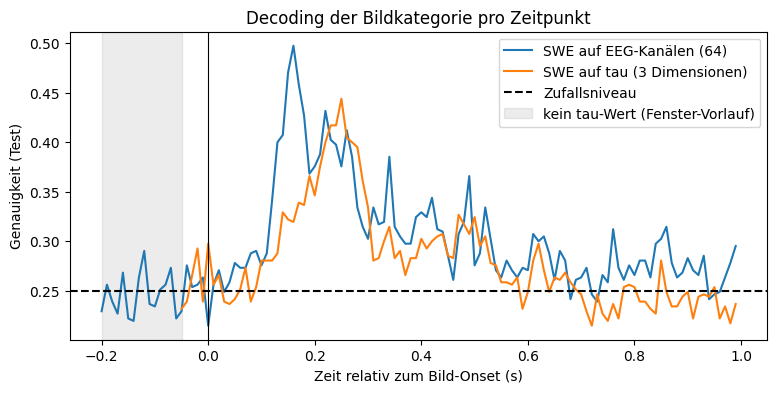

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from mne.decoding import SlidingEstimator, Vectorizer
import matplotlib.pyplot as plt

# Zufallsniveau: Der SWE sagt die Bildkategorie der Epoche vorher
# (ohne die Klasse "vor dem Bild"), also 1 / Anzahl Kategorien.
image_categories = np.unique(train_category_per_epochs_all_subs)
chance_accuracy_for_image_categories = 1 / len(image_categories)
print(f"Bildkategorien: {image_categories}, Zufallsniveau: {chance_accuracy_for_image_categories:.2f}")

# Zeitachse für tau: Jeder latente Wert gehört zum letzten Zeitpunkt seines Fensters.
# Beim zweiten Fenster ist das der Index start + WINDOW_LENGTH,
# also Index WINDOW_LENGTH ... WINDOW_LENGTH + Anzahl Fensterpositionen - 1.
number_of_window_positions = tau_train_values.shape[2]
first_time_index_of_tau = preprocessor.WINDOW_LENGTH
last_time_index_of_tau = first_time_index_of_tau + number_of_window_positions
tau_times = epochs_train.times[first_time_index_of_tau:last_time_index_of_tau]
raw_times = epochs_train.times

# Alle Klassifikatoren: auf den Trainings-Epochen fitten, auf den Test-Epochen bewerten.
# Keine Kreuzvalidierung auf den Trainingsdaten, weil tau die Labels der
# Trainings-Epochen beim Training schon gesehen hat (sonst Leakage).

# lbfgs statt liblinear: liblinear ist für mehr als zwei Klassen veraltet
# und würde für jeden Zeitpunkt eine Warnung ausgeben.

# 1) Ein Klassifikator über alle latenten Dimensionen und alle Zeitpunkte zusammen
spatio_temporal_classifier = make_pipeline(
    Vectorizer(),
    StandardScaler(),
    LogisticRegression(solver="lbfgs", max_iter=1000, random_state=31),
)
spatio_temporal_classifier.fit(train_all_windows_all_epochs, train_category_per_epochs_all_subs)
spatio_temporal_score = spatio_temporal_classifier.score(test_all_windows_all_epochs, test_category_per_epochs_all_subs)
print(f"Spatio-temporal auf tau (Test): {100 * spatio_temporal_score:0.1f}%")

# 2) Sliding Window Estimator auf tau: ein Klassifikator pro Zeitpunkt
tau_sliding_estimator = SlidingEstimator(
    make_pipeline(StandardScaler(), LogisticRegression(solver="lbfgs", max_iter=1000, random_state=41)),
    n_jobs=None,
    scoring="accuracy",
    verbose=True,
)
tau_sliding_estimator.fit(tau_train_values, train_category_per_epochs_all_subs)
tau_scores_per_time_point = tau_sliding_estimator.score(tau_test_values, test_category_per_epochs_all_subs)

# 3) Zum Vergleich: derselbe Sliding Window Estimator auf den rohen EEG-Kanälen
raw_sliding_estimator = SlidingEstimator(
    make_pipeline(StandardScaler(), LogisticRegression(solver="lbfgs", max_iter=1000, random_state=41)),
    n_jobs=None,
    scoring="accuracy",
    verbose=True,
)
raw_sliding_estimator.fit(X_train, train_category_per_epochs_all_subs)
raw_scores_per_time_point = raw_sliding_estimator.score(X_test, test_category_per_epochs_all_subs)

# Plot: beide Kurven auf derselben echten Zeitachse
figure, axis = plt.subplots(figsize=(9, 4))
axis.plot(raw_times, raw_scores_per_time_point, label="SWE auf EEG-Kanälen (64)")
axis.plot(tau_times, tau_scores_per_time_point, label=f"SWE auf tau ({model.latent_dim} Dimensionen)")
axis.axhline(chance_accuracy_for_image_categories, color="k", linestyle="--", label="Zufallsniveau")
axis.axvline(0.0, color="k", linestyle="-", linewidth=0.8)
# Bereich, in dem tau noch kein vollständiges Fenster hat
axis.axvspan(raw_times[0], tau_times[0], color="grey", alpha=0.15, label="kein tau-Wert (Fenster-Vorlauf)")
axis.set_xlabel("Zeit relativ zum Bild-Onset (s)")
axis.set_ylabel("Genauigkeit (Test)")
axis.set_title("Decoding der Bildkategorie pro Zeitpunkt")
axis.legend()
plt.show()